```
Loading dataset
```

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [17]:
df = pd.read_csv("StudentPerformanceFactors.csv")

In [18]:
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [19]:
df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


In [20]:
df.isnull().sum()

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

```
Selecting only the required columns for model training
```

In [21]:
selected_columns = [
    'Attendance',
    'Hours_Studied',
    'Sleep_Hours',
    'Previous_Scores',
    'Tutoring_Sessions',
    'Motivation_Level',
    'Parental_Involvement',
    'Access_to_Resources',
    'Exam_Score'
]

df = df[selected_columns]


In [22]:
df.head()

,Attendance,Hours_Studied,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Motivation_Level,Parental_Involvement,Access_to_Resources,Exam_Score
0,84,23,7,73,0,Low,Low,High,67
1,64,19,8,59,2,Low,Low,Medium,61
2,98,24,7,91,2,Medium,Medium,Medium,74
3,89,29,8,98,1,Medium,Low,Medium,71
4,92,19,6,65,3,Medium,Medium,Medium,70


```
Turning the Low, Medium and High Values in 3 Columns into Numeric Form (0, 0.5, 1)
```

In [23]:
mapping = {
    'Low': 0,
    'Medium': 0.5,
    'High': 1
}

columns = {
    'Motivation_Level',
    'Parental_Involvement',
    'Access_to_Resources'
}

for col in columns:
    df[col] = df[col].map(mapping)

display(df.head())

,Attendance,Hours_Studied,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Motivation_Level,Parental_Involvement,Access_to_Resources,Exam_Score
0,84,23,7,73,0,0.0,0.0,1.0,67
1,64,19,8,59,2,0.0,0.0,0.5,61
2,98,24,7,91,2,0.5,0.5,0.5,74
3,89,29,8,98,1,0.5,0.0,0.5,71
4,92,19,6,65,3,0.5,0.5,0.5,70


In [24]:
df.describe()

,Attendance,Hours_Studied,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Motivation_Level,Parental_Involvement,Access_to_Resources,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000,6607.000000,6607.000000
mean,79.977448,19.975329,7.02906,75.070531,1.493719,0.453231,0.543212,0.550098,67.235659
std,11.547475,5.990594,1.46812,14.399784,1.230570,0.347899,0.347761,0.349173,3.890456
min,60.000000,1.000000,4.00000,50.000000,0.000000,0.000000,0.000000,0.000000,55.000000
25%,70.000000,16.000000,6.00000,63.000000,1.000000,0.000000,0.500000,0.500000,65.000000
50%,80.000000,20.000000,7.00000,75.000000,1.000000,0.500000,0.500000,0.500000,67.000000
75%,90.000000,24.000000,8.00000,88.000000,2.000000,0.500000,1.000000,1.000000,69.000000
max,100.000000,44.000000,10.00000,100.000000,8.000000,1.000000,1.000000,1.000000,101.000000


```
Data Visualization
```

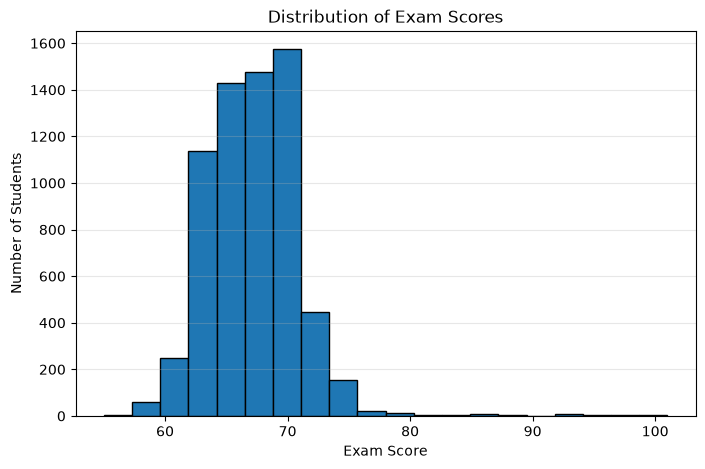

In [25]:
plt.figure(figsize=(8, 5))

plt.hist(df['Exam_Score'], bins=20, edgecolor='black')

plt.title('Distribution of Exam Scores')
plt.xlabel('Exam Score')
plt.ylabel('Number of Students')

plt.grid(axis='y', alpha=0.3)
plt.show()

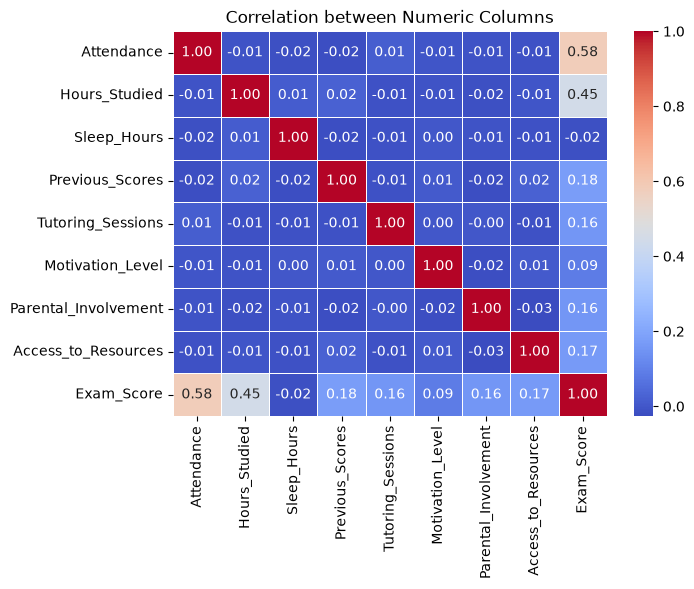

In [26]:
num_cols = df.select_dtypes(include="number")

plt.figure(figsize=(7, 5))
sns.heatmap(num_cols.corr(), annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation between Numeric Columns")
plt.show()

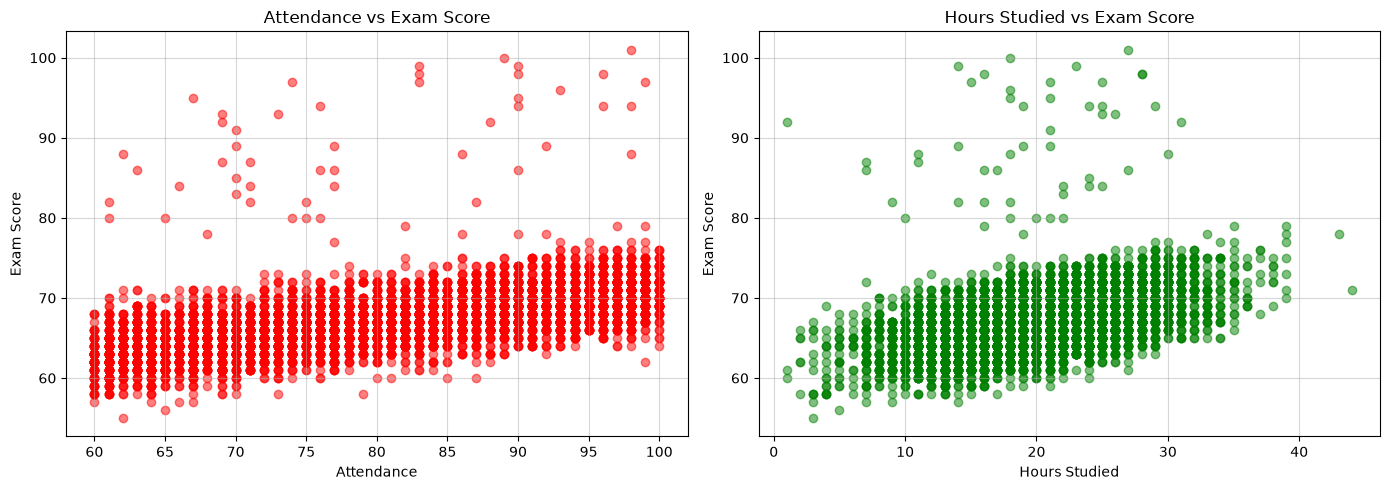

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Attendance vs Exam Score
axes[0].scatter(
    df['Attendance'],
    df['Exam_Score'],
    color='red',
    alpha=0.5
)

axes[0].set_title('Attendance vs Exam Score')
axes[0].set_xlabel('Attendance')
axes[0].set_ylabel('Exam Score')
axes[0].grid(True, alpha=0.5)


# Hours Studied vs Exam Score
axes[1].scatter(
    df['Hours_Studied'],
    df['Exam_Score'],
    color='green',
    alpha=0.5
)

axes[1].set_title('Hours Studied vs Exam Score')
axes[1].set_xlabel('Hours Studied')
axes[1].set_ylabel('Exam Score')
axes[1].grid(True, alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
df.to_csv('student_performance_encoded.csv', index=False)
